# Schedule Personalisation

Demonstrating and quantifying the variation in optimal treatment strategy between patients.

Show both different treatment curves, and also different dependence on tau.

In [1]:
import os
import re
import sys
import pickle
import numpy as np
import pandas as pd
import scipy as sc
import matplotlib.pyplot as plt
from matplotlib.ticker import Locator, MaxNLocator
from matplotlib.colors import LogNorm, to_rgb
from matplotlib import colormaps
from lmfit import minimize, Parameters
from tqdm import tqdm

sys.path.append("../utils")
from myUtils import (calc_critical_treatment_threshold, calc_critical_treatment_interval, calc_delta_benefit,
                     ExtractTreatmentFromDf, GetPatientIDs, calc_threshold_benefit, predict_drug_benefit,
                     calc_threshold_benefit, predict_ct_ttp, predict_atx_ttp, predict_at_threshold_ttp)
from fittingUtils import residual, compute_r_sq, load_fit, generate_fitSummaryDf
from plotUtils import PlotDrug, PlotData, convert_to_rgb_grayscale, redistribute_rgb
from odeModels import LotkaVolterraModel

In [3]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

/var/folders/sr/x0nw2n7d0fjbff6xwtl6dbs80000gn/T/ipykernel_58679/884701199.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([''] + list(colors.keys()));


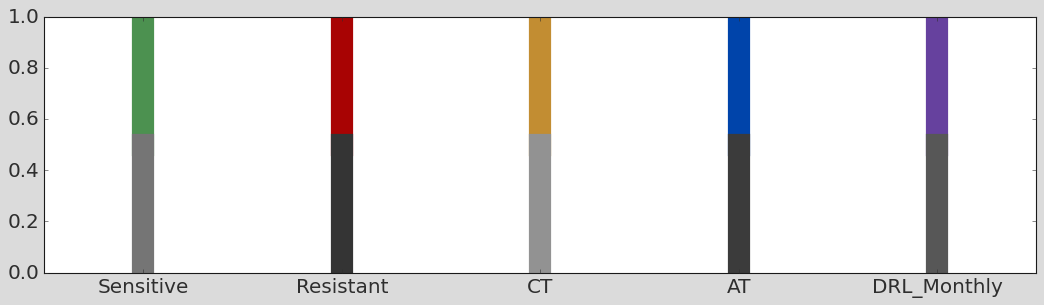

In [4]:
# Defaults for plotting
colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

fig, ax = plt.subplots(1, 1, figsize=(16, 4))
for i, col in enumerate(colors.values()):
    plt.axvline(i+1, 0.5, 1, color = col, linewidth=20)
    plt.axvline(i+1, 0, 0.5, color = convert_to_rgb_grayscale(col), linewidth=20)
plt.xlim(0.5, len(colors.values()) + 0.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().set_xticklabels([''] + list(colors.keys()));

In [5]:
file_path = os.path.dirname(os.path.abspath("__file__"))

out_dir = os.path.join(os.pardir, "patients", "Bruchovsky_et_al", "Prog_fits")

In [6]:
def SimulateFit(fit_params, dataDf, dt=1, solver_kws={}):
    myModel = LotkaVolterraModel()
    myModel.SetParams(**fit_params)
    myModel.Simulate(treatmentScheduleList=ExtractTreatmentFromDf(dataDf),**solver_kws)
    # Interpolate to the desired time grid
    t_eval = np.arange(0, myModel.resultsDf.Time.max(), dt)
    trimmedResultsDic = {'Time': t_eval}
    for variable in ['S', 'R', 'TumourSize', 'DrugConcentration']:
        f = sc.interpolate.interp1d(myModel.resultsDf.Time, myModel.resultsDf[variable])
        trimmedResultsDic = {**trimmedResultsDic, variable: f(t_eval)}
    myModel.resultsDf = pd.DataFrame(trimmedResultsDic)
    return myModel

In [7]:
def Plot_method(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_color = 'k', colors = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    linestyles = ['-', '--', '--']
    for i, var in enumerate(["TumourSize", 'S', 'R']):
        ax.plot(df['Time'], df[var], linewidth=linewidth, linestyle=linestyles[i], color=colors[var], **kwargs)

    PlotDrug(df, ax, drug_color, plotDrugAsBar = True, currDrugBarPosition = 1.25)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)

## Patient Datasets

In [9]:
data_path = "../patients/Bruchovsky_et_al/Prog_data_txt"
patientIds = GetPatientIDs(data_path)
patientsToAnalyseList = patientIds

# Load the data
df = pd.read_csv("patient_fits/full_history_params.csv")
trunc_df = pd.read_csv("patient_fits/first_cycle_params.csv")

n = len(df['PatientId'].unique())
cols = [colormaps['tab10'](i/n) for i in range(n)]
markers = ['v', 's', 'X', 'P', 'o', '*', 'd',]

## Variation in Patient Thresholds


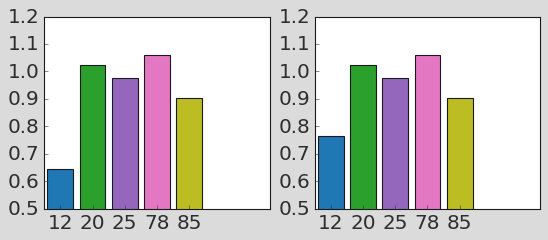

In [10]:
plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(1,2,figsize=(8,3))

ids = np.array(range(len(df.PatientId)))

for ax, df_n in zip(axs, [df, trunc_df]):
    crit_n_star = [calc_critical_treatment_threshold(tau = 30, prog=1.2, \
     **df_n[df_n.PatientId == n].iloc[0].to_dict()) / df_n[df_n.PatientId == n].n0.iloc[0]
       for n in df_n.PatientId]
    ax.bar(ids, crit_n_star, label = "Critical Value", color=cols, width=0.8)
    ax.set_xticks(ids, df_n.PatientId)
      
    ax.set_xlim(-0.5, 6.5), ax.set_ylim(bottom=0.5); 
    ax.tick_params(top=False, right=False)

# ax.set_xlabel("Patient ID"); ax.set_ylabel("Crit Threshold (days)"); 
# plt.legend(loc=1, fontsize=14, numpoints=1)
# plt.gca().legend(loc=1, fontsize=18, numpoints=1).get_frame().\
  # set_boxstyle('Round', pad=0.2, rounding_size=0.5)

_Plot predicted vs actual optimal threshold_

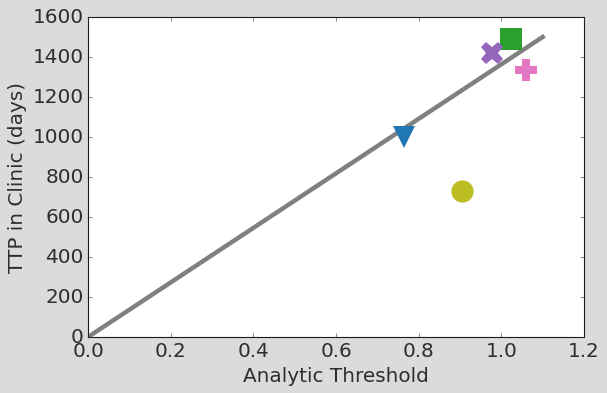

In [11]:
# Critical threshold vs Time in Trial

fig, ax = plt.subplots(1,1,figsize=(8,5))
for n, patient_id in enumerate(df.PatientId):
    ax.plot(crit_n_star[n], df[df.PatientId == patient_id ].TimeInTrial.iloc[0],
             color = cols[n], marker = markers[n], markersize=20,
             markeredgewidth=0)
    
plt.plot([0, ax.get_xlim()[1]], [0, ax.get_ylim()[1]], linestyle = '-', linewidth = 4, zorder=0, color='gray');
# ax.set_xlim(left=0), ax.set_ylim(bottom=0); ax.tick_params(top=False, right=False)
plt.xlabel("Analytic Threshold"); plt.ylabel("TTP in Clinic (days)");

## Variation in importance of tau

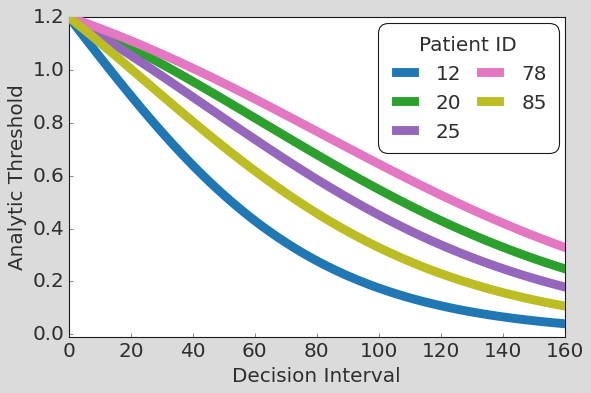

In [12]:
# Prediction

fig, ax = plt.subplots(1,1,figsize=(8,5))

id_list = df.PatientId.values
# id_list = [12, 25]

for n, patient_id in enumerate(id_list):
    odeParamDic = trunc_df[trunc_df.PatientId == patient_id].iloc[0].to_dict()

    tau_values = np.linspace(0, 160, 100)
    n_stars = [calc_critical_treatment_threshold(tau=t,**odeParamDic)
               / trunc_df[trunc_df.PatientId == patient_id].n0.iloc[0] for t in tau_values]
    ax.plot(tau_values, n_stars, linewidth = 8, color=cols[n], zorder=5, label=patient_id) 

legend = plt.legend(loc=1, fontsize=18, ncol=2, title='Patient ID', title_fontsize=18, columnspacing=0.7, handlelength=1.5)
legend.get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)
plt.ylim(-0.01,1.2); ax.tick_params(right = False, top = False)
plt.xlabel("Decision Interval"); plt.ylabel("Analytic Threshold");
plt.savefig("figures/threshold_predictions_all.pdf")


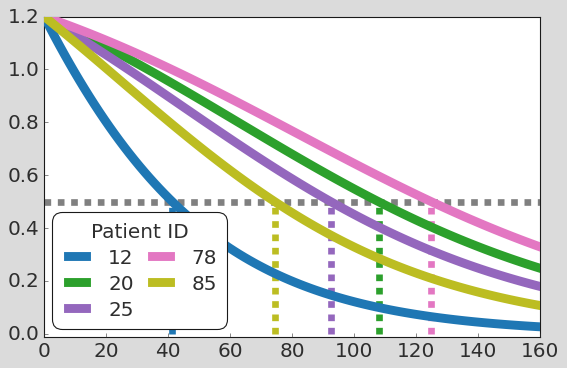

In [13]:
# Reality

fig, ax = plt.subplots(1,1,figsize=(8,5))

id_list = df.PatientId.values
# id_list = [12, 25]

for n, patient_id in enumerate(id_list):
    odeParamDic = df[df.PatientId == patient_id].iloc[0].to_dict()

    tau_values = np.linspace(0, 160, 100)
    n_stars = [calc_critical_treatment_threshold(tau=t,**odeParamDic)
               / df[trunc_df.PatientId == patient_id].n0.iloc[0] for t in tau_values]
    ax.plot(tau_values, n_stars, linewidth = 8, color=cols[n], zorder=5, label=patient_id) 

    val = calc_critical_treatment_interval(n_crit = 0.5 * odeParamDic['n0'],**odeParamDic) 
    ax.vlines(ymin=0, ymax=0.5, x=val, linestyles="--", linewidth=6, color=cols[n])

ax.hlines(xmin=0, xmax=max(tau_values), y=0.5, linestyles="--", linewidth=6, color='gray')

plt.ylim(-0.01,1.2); plt.xlim(0, max(tau_values))
ax.tick_params(right = False, top = False)

legend = plt.legend(loc=3, fontsize=18, ncol=2, title='Patient ID', title_fontsize=18, 
                    columnspacing=0.6, labelspacing=0.35, borderpad=0.3, borderaxespad=0.6, handlelength=1.5)
legend.get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)

# plt.xlabel("Decision Interval"); plt.ylabel("Analytic Threshold");
plt.savefig("figures/threshold_truth_all.pdf")


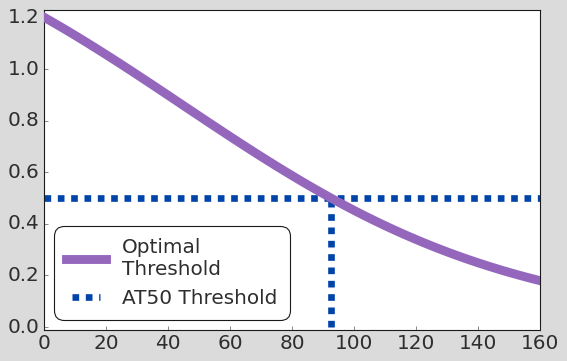

In [14]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(8,5))

patient_id = 25; patient_index = list(id_list).index(patient_id)
n0 = df[df.PatientId == patient_id].n0.iloc[0]
odeParamDic = df[df.PatientId == patient_id].iloc[0].to_dict()

n_stars = [calc_critical_treatment_threshold(tau=t,**odeParamDic)
           / n0 for t in tau_values]
ax.plot(tau_values, n_stars, linewidth = 8, color=cols[patient_index], zorder=5, label = 'Optimal\nThreshold'); 

val = calc_critical_treatment_interval(n_crit = 0.5 * n0,**odeParamDic) 
ax.hlines(xmin=0, xmax=max(tau_values), y=0.5, linestyles="--", linewidth=6, color=colors['AT'])
ax.vlines(ymin=0, ymax=0.5, x=val, linestyles="--", linewidth=6, color=colors['AT'], label='AT50 Threshold')

ax.set_ylim(-0.01,1.23); ax.tick_params(right = False, top = False)
plt.gca().legend(loc=3, fontsize=18, numpoints=1, borderaxespad=0.7).get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)
# plt.xlabel("Decision Interval"); plt.ylabel("Analytic Threshold");
plt.savefig("figures/threshold_truth_example.pdf")

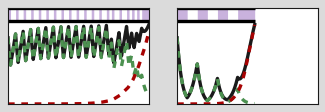

In [15]:
# Plot inserts

fig, axs = plt.subplots(1,2,figsize=(5,1.5), sharex=True)
for i, tau in enumerate([30, 120]):
    ax = axs[i]
    n_star = calc_critical_treatment_threshold(tau=tau,**odeParamDic)/odeParamDic['n0']

    # Simulate and plot model evaluated with decision_interval tau and threshold n_star
    model = LotkaVolterraModel(dt=1)
    model.SetParams(**odeParamDic)
    model.Simulate_AT(atThreshold=n_star, atMethod='Threshold',
                    intervalLength=tau, t_end=6000, refSize = odeParamDic['n0'])
    model.CleanData()
    palette = {'TumourSize': 'k', 'S': colors['Sensitive'], 'R': colors['Resistant']}
    Plot_method(model.resultsDf, ax=ax, legend=False, colors = palette, linewidth=3, drug_color=cols[patient_index])

    ax.set_xticks([]); ax.set_yticks([]); ax.set_ylim(0, 1.45)
plt.savefig("figures/threshold_truth_example_insets.pdf")

In [16]:
def calc_ttp(params, n_crit, interval):
    arg = n_crit/params['n0']
    model = LotkaVolterraModel(dt=1); model.SetParams(**params)
    model.Simulate_AT(atThreshold=arg, atMethod='Threshold',
                    intervalLength=interval, t_end=6000, refSize = params['n0'])
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < 1.2 * params['n0']]
    return model.resultsDf.Time.max()

In [17]:
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import MaxNLocator

# make these smaller to increase the resolution
dx, dy = 1, 0.01

# generate 2 2d grids for the x & y bounds
crit_n_grid, tau_grid = np.mgrid[slice(0, 1.2 + dy, dy),
                slice(1, 161 + dx, dx)]

vectorized_calc_ttp = np.vectorize(calc_ttp)
ttp_values = vectorized_calc_ttp(
    params = odeParamDic, n_crit = crit_n_grid,
    interval = tau_grid
)

ttp_values = ttp_values[:-1, :-1]
fig, ax = plt.subplots()

im = ax.pcolormesh(tau_grid, crit_n_grid, ttp_values, 
                   cmap=plt.get_cmap('viridis'), norm=None)
fig.colorbar(im, ax=ax); #ax.set_title('TTP of Patient 25')
ax.set_xlim(0, np.max(tau_grid)); 
ax.set_xticks(ax.get_xticks()[::2]); 
fig.tight_layout(); 
# plt.savefig("figures/fig5c_bruchovsky_p25_ttp.pdf"); plt.show()

KeyboardInterrupt: 

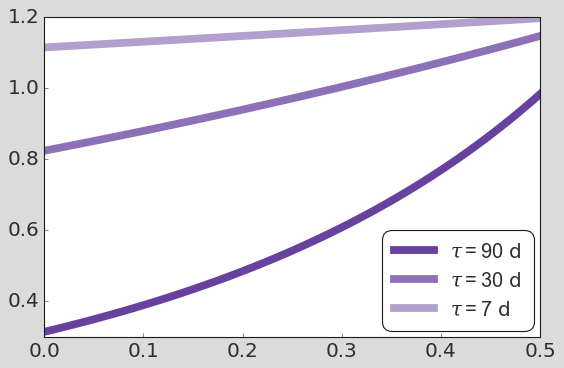

In [ ]:
# Variation with turnover for different treatment time

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(8, 5))

turnover_space = np.linspace(0, 0.5, 100)
n0 = odeParamDic['n0']; rs = odeParamDic['rS']; K = odeParamDic['K']

n_stars_90 = [calc_critical_treatment_threshold(tau=90,S0=n0,K=K, rS = rs, dS=(rs*turnover)) for turnover in turnover_space]
plt.plot(turnover_space, n_stars_90, linewidth = 7, label = r"$\tau = 90$ d", color=colors['DRL_Monthly']); 
n_stars_30 = [calc_critical_treatment_threshold(tau=30,S0=n0,K=K, rS = rs, dS=(rs*turnover)) for turnover in turnover_space]
plt.plot(turnover_space, n_stars_30, linewidth = 7, label = r"$\tau = 30$ d", color=colors['DRL_Monthly'], alpha=0.75); 
n_stars_7 = [calc_critical_treatment_threshold(tau=7,S0=n0,K=K, rS = rs, dS=(rs*turnover)) for turnover in turnover_space]
plt.plot(turnover_space, n_stars_7, linewidth = 7, label = r"$\tau = 7$ d", color=colors['DRL_Monthly'], alpha=0.5); 
# plt.xlabel("Turnover"); plt.ylabel("Analytic Threshold"); 
ax.tick_params(right = False, top = False)
plt.gca().legend(loc=4, fontsize=18, numpoints=1).get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)
plt.savefig("figures/p25_threshold_vs_turnover.pdf")

## Case Study group

In [18]:
keep_ids = df.PatientId.values
df_subset = df[df.PatientId.isin(keep_ids)]
trunc_subset = trunc_df[trunc_df.PatientId.isin(keep_ids)]

cols_subset = [cols[df.PatientId.tolist().index(i)] for i in keep_ids]

[np.float64(0.22131065003115075), np.float64(0.024230547582418365)]
[np.float64(0.612590556452086), np.float64(0.18354359412475735)]
[np.float64(0.5164342190238285), np.float64(0.12762164680396484)]
[np.float64(0.705704594809672), np.float64(0.25228827797705755)]
[np.float64(0.38922054511438736), np.float64(0.07204756663446649)]


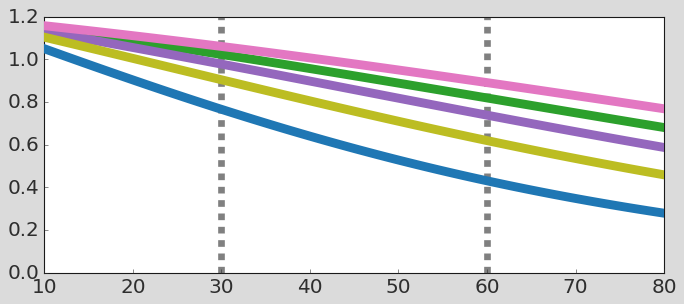

In [19]:
fig, ax = plt.subplots(1,1,figsize=(10,4))
for n, patient_id in enumerate(keep_ids):
    odeParamDic = trunc_subset[trunc_subset.PatientId == patient_id].iloc[0].to_dict()

    tau_values = np.linspace(10, 80, 81)
    n_stars = [calc_critical_treatment_threshold(tau=t,**odeParamDic)
               / trunc_subset[trunc_subset.PatientId == patient_id].n0.iloc[0] for t in tau_values]
    ax.plot(tau_values, n_stars, linewidth = 8, color=cols_subset[n], zorder=5)

    print([calc_critical_treatment_threshold(tau=t,**odeParamDic)
               / trunc_subset[trunc_subset.PatientId == patient_id].n0.iloc[0] for t in [90, 180]])
    
#     closest_tau = tau_values[np.argmin(np.abs(np.array(n_stars) - 1))]
#     ax.vlines(ymin=0, ymax=1, x=closest_tau, linestyles="--", linewidth=2, color=cols_subset[n], zorder=10)
# ax.hlines(xmin=min(tau_values), xmax=max(tau_values), y=1, linestyles="--", linewidth=2, color='gray', zorder=10)

ax.vlines(ymin=0, ymax=1.2, x=30, linestyles="--", linewidth=6, color="gray")
ax.vlines(ymin=0, ymax=1.2, x=60, linestyles="--", linewidth=6, color="gray")
ax.tick_params(right = False, top = False)

# plt.xlabel("Decision Interval"); plt.ylabel("Analytic Threshold");
plt.savefig("figures/fig4c_selected_n_crit.pdf")

[np.float64(0.10390607632557788), np.float64(0.010412825410750648)]
[np.float64(0.6830397664130173), np.float64(0.13842878748815254)]
[np.float64(0.4600578674797093), np.float64(0.0844419040366968)]
[np.float64(1.0073711098418663), np.float64(0.21862880988607528)]
[np.float64(0.26380196351766116), np.float64(0.040191658297064184)]


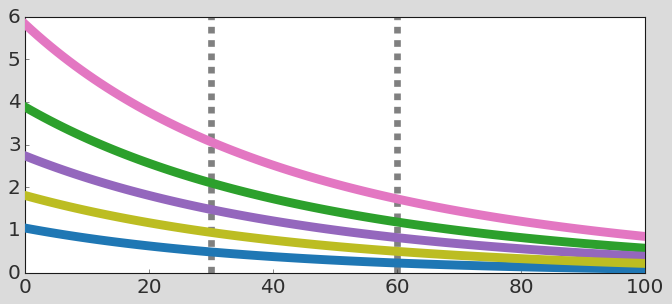

In [20]:
fig, ax = plt.subplots(1,1,figsize=(10,4))
for n, patient_id in enumerate(keep_ids):
    odeParamDic = trunc_subset[trunc_subset.PatientId == patient_id].iloc[0].to_dict()

    tau_values = np.linspace(0, 100, 100)
    n_stars = [calc_threshold_benefit(tau=t,**odeParamDic) for t in tau_values]
    ax.plot(tau_values, n_stars, linewidth = 8, color=cols_subset[n], zorder=5)

    print([calc_threshold_benefit(tau=t,**odeParamDic) for t in [90, 180]])

y_max = plt.gca().get_ylim()[1]
ax.vlines(ymin=0, ymax=y_max, x=30, linestyles="--", linewidth=6, color="gray")
ax.vlines(ymin=0, ymax=y_max, x=60, linestyles="--", linewidth=6, color="gray")
ax.tick_params(right = False, top = False)

# plt.ylim(-0.01,1.2)
# plt.xlabel("Decision Interval"); plt.ylabel(r"$\Delta T(N^{*})$");
plt.savefig("figures/fig4c_selected_benefit.pdf")

[np.float64(599.4026561571516), np.float64(548.6373744606801)]
[np.float64(1523.3522441365026), np.float64(1030.4141843931307)]
[np.float64(1192.5906680044434), np.float64(885.7835867694524)]
[np.float64(1999.4329114548152), np.float64(1213.8097123083417)]
[np.float64(887.4252810810511), np.float64(730.4090366920348)]


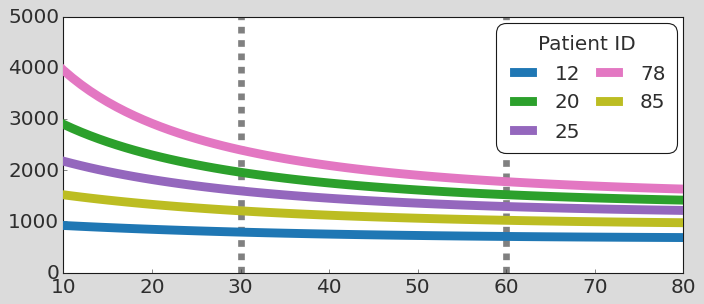

In [21]:
fig, ax = plt.subplots(1,1,figsize=(10,4))
for n, patient_id in enumerate(keep_ids):
    odeParamDic = trunc_subset[trunc_subset.PatientId == patient_id].iloc[0].to_dict()

    tau_values = np.linspace(0, 80, 81)
    ttp_est = [predict_atx_ttp(tau=t, upper = odeParamDic['n0'] * 0.2, 
                               n_lim = odeParamDic['n0']*0.6, **odeParamDic) 
               for t in tau_values]
    ax.plot(tau_values, ttp_est, linewidth = 8, color=cols_subset[n], zorder=5, label=patient_id)

    print([predict_at_threshold_ttp(tau=t,**odeParamDic)for t in [90, 180]])

y_max = plt.gca().get_ylim()[1]
ax.vlines(ymin=0, ymax=y_max, x=30, linestyles="--", linewidth=6, color="gray")
ax.vlines(ymin=0, ymax=y_max, x=60, linestyles="--", linewidth=6, color="gray")
ax.tick_params(right = False, top = False)

legend = plt.legend(loc=1, fontsize=18, ncol=2, title='Patient ID', title_fontsize=18, columnspacing=0.7, handlelength=1.5)
legend.get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)

plt.xlim(left=10); plt.ylim(0, 5000)
# plt.xlabel("Decision Interval"); plt.ylabel("TTP estimate");
plt.savefig("figures/fig4c_selected_ttp_pred.pdf")

In [22]:
def calc_best_ttp(params, interval):
    n_crit = calc_critical_treatment_threshold(tau = interval, **params)
    arg = n_crit/params['n0']
    # print(n_crit, arg, interval)
    model = LotkaVolterraModel(dt=1); model.SetParams(**params)
    model.Simulate_AT(atThreshold=arg, atMethod='Threshold',
                    intervalLength=interval, t_end=6000, refSize = params['n0'])
    model.resultsDf = model.resultsDf[model.resultsDf.TumourSize < 1.2 * params['n0']]
    # model.Plot(plotPops=True, legend=False)
    # plt.gcf().get_axes()[0].get_legend().remove()
    return model.resultsDf.Time.max()

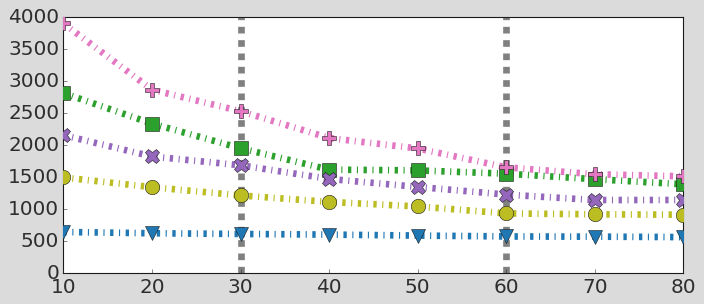

In [23]:
subsampled_tau_values = tau_values[10::10]

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(10,4))
for n, patient_id in enumerate(keep_ids):
    odeParamDic = df_subset[df_subset.PatientId == patient_id].iloc[0].to_dict()

    ttp_vals = [calc_best_ttp(odeParamDic, int(t)) for t in subsampled_tau_values]

    ax.plot(subsampled_tau_values, ttp_vals, linewidth=6, linestyle='-.', color=cols_subset[n],
            zorder=5, label="Patient " + str(patient_id), marker=markers[n], markersize=13)

ax.vlines(ymin=0, ymax=ax.get_ylim()[1], x=30, linestyles="--", linewidth=6, color="gray")
ax.vlines(ymin=0, ymax=ax.get_ylim()[1], x=60, linestyles="--", linewidth=6, color="gray")
ax.tick_params(right = False, top = False)

# plt.legend(loc=1).get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)
# plt.xlabel("Decision Interval"); plt.ylabel("TTP (days)");
plt.savefig("figures/fig4d_bruch_max_ttp.pdf")

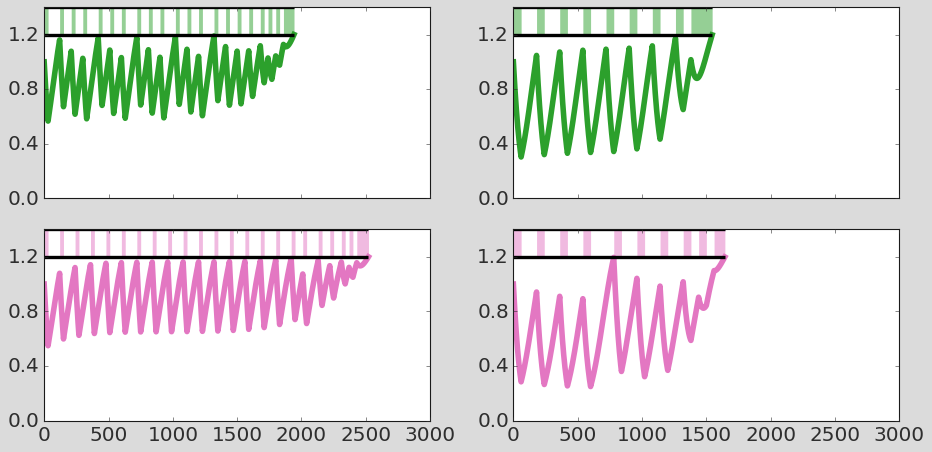

In [24]:
plt.rcParams['font.size'] = '18'
fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True)

for n, patient_id in enumerate([20, 78]):
    params = df_subset[df_subset.PatientId == patient_id].iloc[0].to_dict()
    plot_cols = [cols_subset[list(keep_ids).index(patient_id)]]*2

    for m, (interval, color) in enumerate(zip([30, 60], plot_cols)):
        n_crit = calc_critical_treatment_threshold(tau = interval, **params)
        arg = n_crit/params['n0']
        # print(n_crit, arg, interval)
        at_model = LotkaVolterraModel(dt=1); at_model.SetParams(**params)
        at_model.Simulate_AT(atThreshold=arg, atMethod='Threshold',
                        intervalLength=interval, t_end=5000, refSize = params['n0'])
        at_model.CleanData(); 
        axs[n][m].plot(at_model.resultsDf.Time, at_model.resultsDf.TumourSize,
                                color=color, linewidth=5)
        # axs[n][m].hlines(y=arg, xmin=0, xmax=max(at_model.resultsDf.Time), color='gray', linestyle='--', linewidth=3)
        PlotDrug(at_model.resultsDf, axs[n][m], color=color)
        axs[n][m].set_ylim(0, 1.4)
        # axs[n][m].set_xticks(axs[n][m].get_xticks()[::2])
        axs[n][m].set_yticks(axs[n][m].get_yticks()[::2])

    # axs[0][n].set_title(patient_id); 
    # axs[1][n].set_xlim(axs[0][n].get_xlim())

ax.tick_params(right = False, top = False)
plt.tight_layout()
plt.savefig("figures/fig4d_bruch_examples.pdf")
    

## Metric Scores

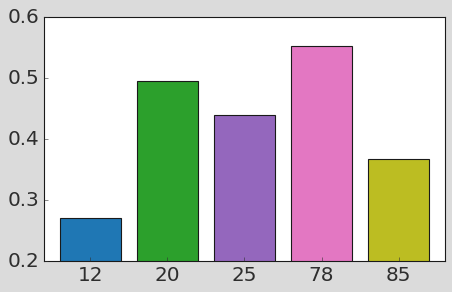

In [25]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1 ,figsize=(6,4))
    
def doubling_benefit_wrapper(row):
    kappa = 0.5 * row.n0 / row.K  # 50% threshold, accounting for kappa scaling
    return calc_delta_benefit(kappa=kappa, **row.to_dict())
  
doubling = [doubling_benefit_wrapper(trunc_df[trunc_df.PatientId == n].iloc[0])
            for n in keep_ids]


plt.bar(range(len(doubling)), doubling, color=[cols[n] for n in range(len(doubling))])

ax.set_xticks(range(len(doubling)))
ax.set_xticklabels(keep_ids)
ax.set_xlim(-0.6, len(doubling)-0.4);
ax.set_ylim(0.2, 0.6); ax.set_yticks(ax.get_yticks()[::2])
ax.tick_params(top=False, right=False)

# plt.xlabel("Patient ID"); plt.ylabel("Delta AT Score")

plt.tight_layout()
plt.savefig("figures/fig4_delta_at_scores.pdf")

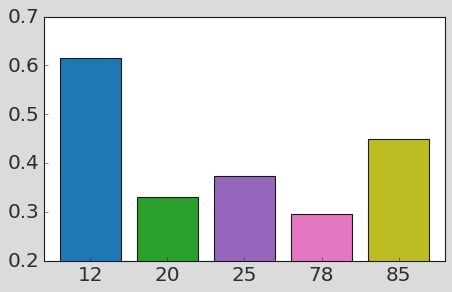

In [26]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1 ,figsize=(6,4))


mdd_vals= [predict_drug_benefit(tau=30, n_crit = 0.5 * trunc_df[trunc_df.PatientId == n].n0.values[0],
                                 **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict())
    for n in keep_ids]


plt.bar(range(len(mdd_vals)), mdd_vals, color=[cols[n] for n in range(len(mdd_vals))])

ax.set_xticks(range(len(mdd_vals)))
ax.set_xticklabels(keep_ids)
ax.set_xlim(-0.6, len(mdd_vals)-0.4)
ax.set_ylim(0.2, 0.7); #ax.set_yticks(ax.get_yticks()[::2])
ax.tick_params(top=False, right=False)

# plt.xlabel("Patient ID"); plt.ylabel("eMDD Score")

plt.tight_layout()
plt.savefig("figures/fig4_eMDD_scores.pdf")

In [27]:
exp_ct = [predict_ct_ttp(**trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]
exp_at = [predict_at_threshold_ttp(tau=60, **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]
exp_at_plus = [predict_at_threshold_ttp(tau=30, **trunc_df[trunc_df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]

labels = ['CT', 'AT', 'AT+']

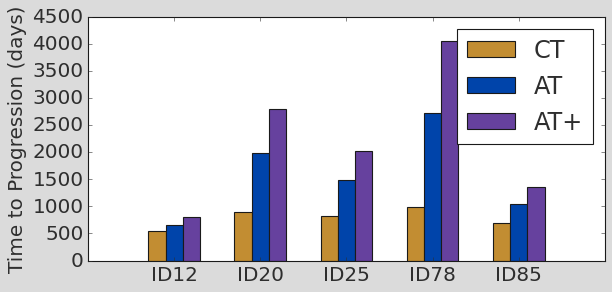

In [28]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1 ,figsize=(8,4))
    

width = 0.2  # width of the bars
x = np.arange(len(keep_ids))  # the label locations

# Plot bars for each strategy
ax.bar(x - width, exp_ct, width, label='CT', color=colors['CT'])
ax.bar(x, exp_at, width, label='AT', color=colors['AT'])
ax.bar(x + width, exp_at_plus, width, label='AT+', color=colors['DRL_Monthly'])

# Add labels, title, and legend
ax.set_xticks(x)
ax.set_xticklabels([f"ID{pid}" for pid in keep_ids])
ax.set_ylabel("Time to Progression (days)")
ax.legend()

plt.tight_layout()
plt.savefig("figures/fig4_eTTP_scores.pdf")

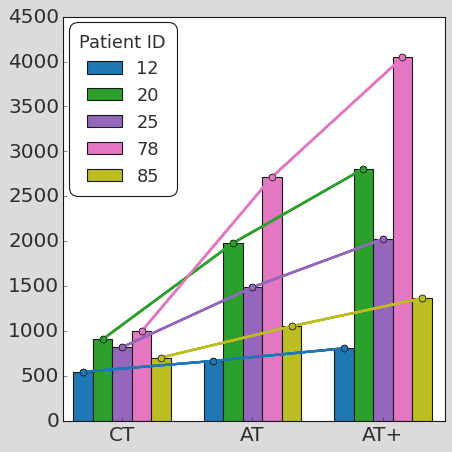

In [29]:
# Define the positions for the bars
x = np.arange(len(labels))  # CT, AT, AT+
width = 0.15  # width of the bars

# Create the plot
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(6, 6))

# Plot bars for each patient
for i, patient_id in enumerate(keep_ids):
    ax.bar(x + (i - 1) * width, [exp_ct[i], exp_at[i], exp_at_plus[i]], width, label=patient_id, color=cols[i])
    # Add lines joining the tops of each bar
    for i in range(len(keep_ids)):
        ax.plot(x + (i - 1) * width, [exp_ct[i], exp_at[i], exp_at_plus[i]], color=cols[i], linewidth=2, marker='o')

# Add labels, title, and legend
ax.set_xticks(x + width)
ax.set_xticklabels(labels)
ax.set_xlim(-width*2, len(labels)-width*2.5)
# ax.set_ylabel("eTTP Score (days)")
# ax.set_title("Comparison of CT, AT, and AT+ Strategies")
legend = ax.legend(title="Patient ID", fontsize=16, title_fontsize=16, loc=2)
legend.get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)
ax.tick_params(top=False, right=False)

# Show the plot
plt.tight_layout()
plt.savefig("figures/fig4_eTTP_scores_comparison.svg")

In [30]:
real_ct = [predict_ct_ttp(**df[df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]
real_at = [predict_at_threshold_ttp(tau=60, **df[df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]
real_at_plus = [predict_at_threshold_ttp(tau=30, **df[df.PatientId == n].iloc[0].to_dict()) for n in keep_ids]

labels = ['CT', 'AT', 'AT+']

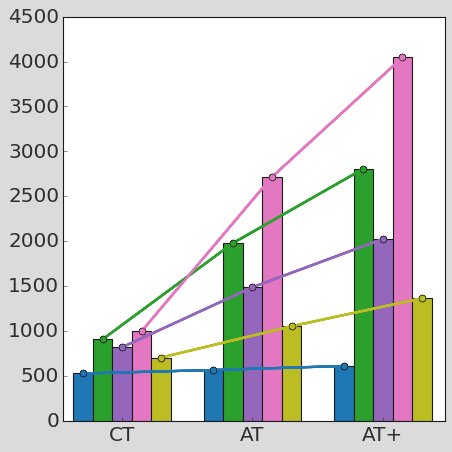

In [31]:
# Define the positions for the bars
x = np.arange(len(labels))  # CT, AT, AT+
width = 0.15  # width of the bars

# Create the plot
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(figsize=(6, 6))

# Plot bars for each patient
for i, patient_id in enumerate(keep_ids):
    ax.bar(x + (i - 1) * width, [real_ct[i], real_at[i], real_at_plus[i]], width, label=patient_id, color=cols[i])
    # Add lines joining the tops of each bar
    for i in range(len(keep_ids)):
        ax.plot(x + (i - 1) * width, [real_ct[i], real_at[i], real_at_plus[i]], color=cols[i], linewidth=2, marker='o')

# Add labels, title, and legend
ax.set_xticks(x + width)
ax.set_xticklabels(labels)
ax.set_xlim(-width*2, len(labels)-width*2.5)
# ax.set_ylabel("Time to Progression (days)")
# ax.set_title("Comparison of CT, AT, and AT+ Strategies")
# ax.legend(title="Patient ID", fontsize=16, title_fontsize=16, loc=2)
ax.tick_params(top=False, right=False)

# Show the plot
plt.tight_layout()
plt.savefig("figures/fig4_TTP_simulations.svg")
plt.show()